# Historical rainfall and climatology for a basin

Prepare **past monthly rainfall** and the **MERGE monthly climatology** for a basin
polygon, following the geometry and downloader conventions of notebook 07.
Only a GeoParquet with a defined CRS and the MERGE download/cache directory are needed.
All selected polygon rows form one analysis region.

The workflow loads observations and a twelve-month climatology, clips each native grid,
compares basin rainfall with its monthly normal, and maps a selected month.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import xarray as xr
from IPython.display import display as ipython_display
from mergedownloader.downloader import Downloader
from mergedownloader.file_downloader import DownloadMode, FileDownloader
from mergedownloader.inpeparser import InpeParsers, InpeTypes
from mergedownloader.utils import GISUtil

## Configuration and basin geometry

Use the same basin example as notebook 07, or change `BASIN_PATH` and `BASIN_NAME`.
Select polygon rows explicitly after reading if the file contains several basins.
The clipping helper reprojects the geometry to each raster CRS.

`START_MONTH` and `END_MONTH` are inclusive calendar months, written as `YYYY-MM-01`.
`MAP_MONTH` must fall inside this range. The example runs from September 2025 through October 2026, using completed months.
Move the end month forward only after the required observations are available.

`DOWNLOAD_MODE = DownloadMode.NO_UPDATE` reuses cached products and downloads missing
files. A completed calendar month can still have a **partial cached accumulation**.
Before interpreting deficits, check the cached monthly NetCDF attributes `days` and
`last_day` against the calendar. Delete an incomplete monthly cache file and rerun
once all daily inputs are available. This workflow does not certify daily completeness.

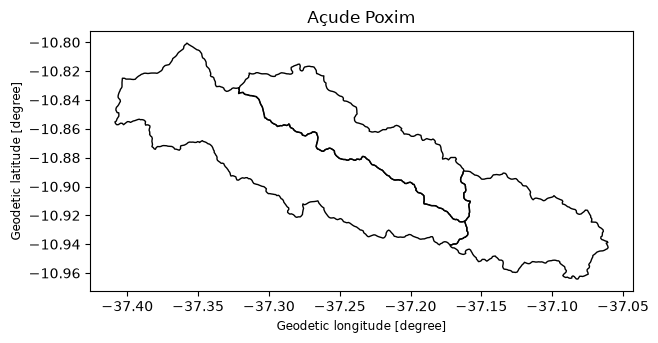

In [2]:
DATA_DIR = Path("/data/CN3S")
BASIN_PATH = Path("/data/CN3S/basins/Timbo/Timbo_SE.parquet")
BASIN_NAME = "Açude Poxim"
START_MONTH = "2025-09-01"
END_MONTH = "2026-10-01"
MAP_MONTH = "2026-10-01"
DOWNLOAD_MODE = DownloadMode.NO_UPDATE

basin = gpd.read_parquet(BASIN_PATH)
if basin.crs is None:
    msg = "Basin geometry must have a defined CRS."
    raise ValueError(msg)

ax = basin.plot(facecolor="none", edgecolor="black", figsize=(7, 5))
ax.set_title(BASIN_NAME)
plt.show()

In [3]:
start = pd.Timestamp(START_MONTH).to_period("M").to_timestamp()
end = pd.Timestamp(END_MONTH).to_period("M").to_timestamp()
current_month = pd.Timestamp.now(tz="America/Sao_Paulo").tz_localize(None).to_period("M")
if start > end or end.to_period("M") >= current_month:
    msg = "Choose an ordered historical range ending before the current calendar month."
    raise ValueError(msg)
months = pd.date_range(start, end, freq="MS")

map_month = pd.Timestamp(MAP_MONTH).to_period("M").to_timestamp()
if map_month not in months:
    msg = "MAP_MONTH must be inside the configured historical range."
    raise ValueError(msg)

downloader = Downloader(
    file_downloader=FileDownloader(download_mode=DOWNLOAD_MODE),
    local_folder=str(DATA_DIR / "downloads"),
    parsers=InpeParsers,
)

Using HTTP downloads


## Historical monthly rainfall

Use `MONTHLY_ACCUM_MANUAL`, the same observed product as notebook 07. The downloader
sums daily MERGE rainfall into calendar-month accumulations and caches the result.
A long uncached period may require many daily downloads and substantial memory;
start with a short period. Dates select months, rather than a historical data snapshot.

MERGE rainfall is in mm (equivalent to kg m⁻² of water). Normalize its month labels
from the source timestamps to month starts **after checking that every requested
month is present**. This keeps comparison with climatology explicit.

In [4]:
observed_grid = downloader.create_cube(
    months[0].to_pydatetime(),
    months[-1].to_pydatetime(),
    InpeTypes.MONTHLY_ACCUM_MANUAL,
)
observed_months = pd.DatetimeIndex(observed_grid.time.to_numpy()).to_period("M")
if not observed_months.equals(months.to_period("M")):
    msg = "Observed rainfall does not contain every requested month in order; check downloads."
    raise ValueError(msg)
observed_grid = observed_grid.assign_coords(time=months)
observed = GISUtil.cut_cube_by_geoms(observed_grid, basin.geometry)
observed.attrs.update(units="mm", long_name="Observed monthly rainfall accumulation")

observed_data = xr.Dataset(
    {
        "rainfall": observed,
        "basin_mean": observed.mean(dim=["latitude", "longitude"]).assign_attrs(
            units="mm", long_name="Basin mean observed monthly rainfall"
        ),
    },
    attrs={"basin_name": BASIN_NAME, "source_product": "MONTHLY_ACCUM_MANUAL"},
)
observed_data

<xarray.Dataset> Size: 560B
Dimensions:      (latitude: 2, longitude: 3, time: 14)
Coordinates:
  * latitude     (latitude) float64 16B -10.95 -10.85
  * longitude    (longitude) float64 24B -37.35 -37.25 -37.15
  * time         (time) datetime64[ns] 112B 2025-09-01 2025-10-01 ... 2026-10-01
    surface      float64 8B ...
    spatial_ref  int64 8B 0
Data variables:
    rainfall     (time, latitude, longitude) float32 336B nan nan ... 10.62 nan
    basin_mean   (time) float32 56B 100.5 79.73 21.06 ... 69.54 25.54 8.375
Attributes:
    basin_name:      Açude Poxim
    source_product:  MONTHLY_ACCUM_MANUAL

## Twelve-month rainfall climatology

`MONTHLY_ACCUM` is the **supplied MERGE mean monthly accumulation**, rather than a
mean estimated from the selected historical window. The installed downloader documents
this product as the mean of 2000–2023 monthly totals. Confirm the reference period
with the source when changing the installed parser or cached product.

Load one January–December cycle and replace the product's reference-year timestamps
with a `month` coordinate (1–12). The arbitrary request year only selects filenames;
it does not set the climatological baseline. Preserve the native grid independently
of the observation grid.

In [5]:
climatology_dates = pd.date_range("2001-01-01", periods=12, freq="MS")
climatology_grid = downloader.create_cube(
    climatology_dates[0].to_pydatetime(),
    climatology_dates[-1].to_pydatetime(),
    InpeTypes.MONTHLY_ACCUM,
)
if not np.array_equal(climatology_grid.time.dt.month.to_numpy(), climatology_dates.month):
    msg = "Climatology must contain one January-December cycle in order; check downloads."
    raise ValueError(msg)
climatology_grid = (
    climatology_grid.assign_coords(month=("time", climatology_dates.month))
    .swap_dims({"time": "month"})
    .drop_vars("time")
)
climatology = GISUtil.cut_cube_by_geoms(climatology_grid, basin.geometry)
climatology.attrs.update(units="mm", long_name="MERGE mean monthly rainfall accumulation")

climatology_data = xr.Dataset(
    {
        "rainfall": climatology,
        "basin_mean": climatology.mean(dim=["latitude", "longitude"]).assign_attrs(
            units="mm", long_name="Basin mean monthly rainfall climatology"
        ),
    },
    attrs={"basin_name": BASIN_NAME, "source_product": "MONTHLY_ACCUM"},
)

rainfall_data = {"observed": observed_data, "climatology": climatology_data}
rainfall_data

{'observed': <xarray.Dataset> Size: 560B
 Dimensions:      (latitude: 2, longitude: 3, time: 14)
 Coordinates:
   * latitude     (latitude) float64 16B -10.95 -10.85
   * longitude    (longitude) float64 24B -37.35 -37.25 -37.15
   * time         (time) datetime64[ns] 112B 2025-09-01 2025-10-01 ... 2026-10-01
     surface      float64 8B ...
     spatial_ref  int64 8B 0
 Data variables:
     rainfall     (time, latitude, longitude) float32 336B nan nan ... 10.62 nan
     basin_mean   (time) float32 56B 100.5 79.73 21.06 ... 69.54 25.54 8.375
 Attributes:
     basin_name:      Açude Poxim
     source_product:  MONTHLY_ACCUM_MANUAL,
 'climatology': <xarray.Dataset> Size: 768B
 Dimensions:      (longitude: 3, latitude: 2, month: 12)
 Coordinates:
   * longitude    (longitude) float64 24B -37.35 -37.25 -37.15
   * latitude     (latitude) float64 16B -10.95 -10.85
   * month        (month) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
     spatial_ref  int64 8B 0
 Data variables:
     rainfall     (

## Basin rainfall and departures from climatology

As in notebook 07, basin rainfall is the **arithmetic mean of valid grid cells**
inside the polygon mask. It is not weighted by cell area or polygon intersection area.
Cells outside the basin are masked; missing cells inside the basin are also skipped
by the mean. Inspect the native grids if spatial coverage changes.

Match the climatological basin mean to each observation's calendar month.
`anomaly_mm = observed_mm − climatology_mm` and
`anomaly_pct = 100 × anomaly_mm / climatology_mm`.
Percentage anomalies are undefined when climatology is zero; retain them as missing
values rather than replacing them with zero. These are anomalies of **basin means**,
not averages of cellwise percentage anomalies. Missing basin rainfall stops processing.

In [6]:
monthly = pd.DataFrame(
    {
        "observed_mm": observed_data["basin_mean"].to_numpy(),
        "climatology_mm": climatology_data["basin_mean"].sel(month=months.month).to_numpy(),
    },
    index=pd.DatetimeIndex(months, name="month"),
)
if monthly.isna().any().any():
    msg = "Basin rainfall or climatology is missing; inspect raster coverage before comparison."
    raise ValueError(msg)
monthly["anomaly_mm"] = monthly["observed_mm"] - monthly["climatology_mm"]
monthly["anomaly_pct"] = (
    100 * monthly["anomaly_mm"] / monthly["climatology_mm"].where(monthly["climatology_mm"] > 0)
)
monthly.round(2)

,observed_mm,climatology_mm,anomaly_mm,anomaly_pct
month,,,,
2025-09-01,100.519997,55.47,45.05,81.21
2025-10-01,79.730003,32.76,46.97,143.40
2025-11-01,21.059999,31.83,-10.77,-33.83
2025-12-01,1.210000,24.92,-23.71,-95.15
2026-01-01,25.020000,45.09,-20.07,-44.51
2026-02-01,72.169998,52.23,19.93,38.16
2026-03-01,57.169998,70.05,-12.89,-18.39
2026-04-01,196.899994,125.14,71.75,57.34
2026-05-01,107.650002,194.91,-87.26,-44.77


In [7]:
fig = go.Figure()
fig.add_bar(x=monthly.index, y=monthly["observed_mm"], name="Observed rainfall")
fig.add_scatter(
    x=monthly.index,
    y=monthly["climatology_mm"],
    name="MERGE climatology",
    mode="lines+markers",
    line={"color": "black"},
)
fig.update_layout(
    title=f"Monthly rainfall and climatology — {BASIN_NAME}",
    xaxis_title="Month",
    yaxis_title="Rainfall (mm)",
    template="plotly_white",
    hovermode="x unified",
)
fig.show()

In [8]:
for column, unit in (("anomaly_mm", "mm"), ("anomaly_pct", "%")):
    fig = go.Figure(
        go.Bar(
            x=monthly.index,
            y=monthly[column],
            marker_color=np.where(monthly[column] >= 0, "steelblue", "indianred"),
            name=f"Anomaly ({unit})",
        )
    )
    fig.add_hline(y=0, line_color="black", line_width=1)
    fig.update_layout(
        title=f"Observed rainfall anomaly — {BASIN_NAME}",
        xaxis_title="Month",
        yaxis_title=f"Observed - climatology ({unit})",
        template="plotly_white",
    )
    fig.show()

## Climatological annual cycle

This table and chart show the twelve supplied monthly normals, independently of the
historical window. Their sum is the climatological annual rainfall total in mm/year.

In [9]:
climatology_table = climatology_data["basin_mean"].to_series().rename("climatology_mm").to_frame()
ipython_display(climatology_table.round(2))
print(f"Climatological annual rainfall: {climatology_table['climatology_mm'].sum():.1f} mm/year")

fig = go.Figure(
    go.Bar(
        x=climatology_table.index,
        y=climatology_table["climatology_mm"],
        name="MERGE climatology",
    )
)
fig.update_layout(
    title=f"Climatological monthly rainfall — {BASIN_NAME}",
    xaxis={"title": "Calendar month", "tickmode": "linear", "dtick": 1},
    yaxis_title="Rainfall (mm)",
    template="plotly_white",
)
fig.show()

,climatology_mm
month,
1,45.09
2,52.23
3,70.05
4,125.14
5,194.91
6,170.95
7,150.12
8,90.76
9,55.47


Climatological annual rainfall: 1044.2 mm/year


## Spatial comparison for a selected month

Compare observed rainfall in `MAP_MONTH` with that calendar month's climatology.
Both panels use the same colour limits in mm and show the basin outline reprojected
to the raster CRS. Each raster retains its native grid; no interpolation or resampling
is needed for these side-by-side maps. This preserves the distinction between the
historical field and the climatological field.

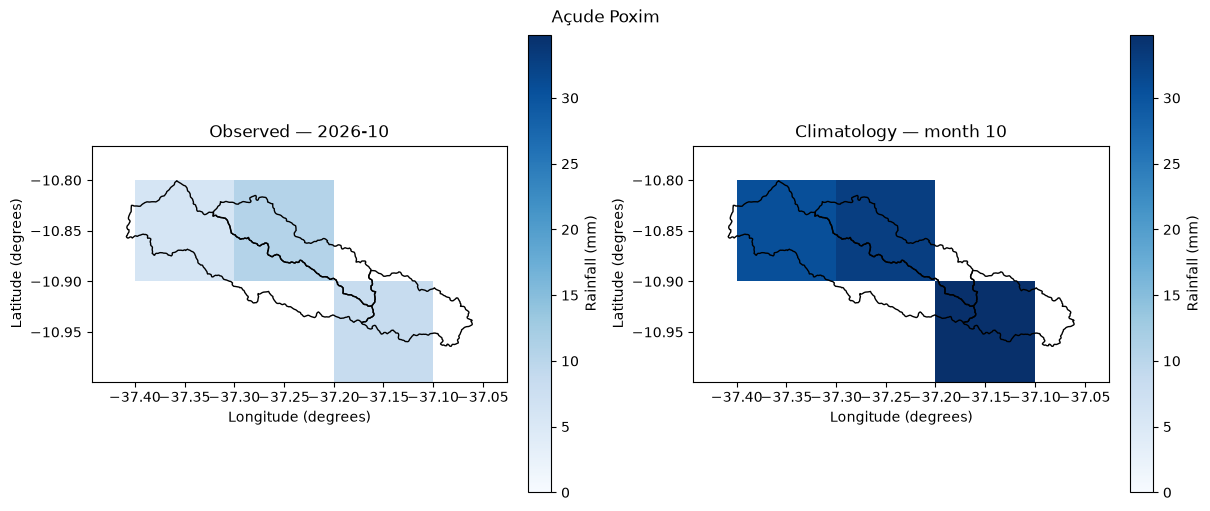

In [10]:
observed_map = observed_data["rainfall"].sel(time=map_month)
climatology_map = climatology_data["rainfall"].sel(month=map_month.month)
vmax = max(float(observed_map.max()), float(climatology_map.max()), 1.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, field, title in zip(
    axes,
    (observed_map, climatology_map),
    (f"Observed — {map_month:%Y-%m}", f"Climatology — month {map_month.month:02d}"),
    strict=True,
):
    field.plot(
        ax=ax,
        x="longitude",
        y="latitude",
        cmap="Blues",
        vmin=0,
        vmax=vmax,
        cbar_kwargs={"label": "Rainfall (mm)"},
    )
    map_basin = basin.to_crs(field.rio.crs)
    map_basin.boundary.plot(ax=ax, color="black", linewidth=1)
    # Include the full polygon even where the clipped grid has no cell centres.
    xmin, ymin, xmax, ymax = map_basin.total_bounds
    padding = 0.1 * max(xmax - xmin, ymax - ymin)
    ax.set_xlim(xmin - padding, xmax + padding)
    ax.set_ylim(ymin - padding, ymax + padding)
    ax.set_title(title)
    ax.set_xlabel("Longitude (degrees)")
    ax.set_ylabel("Latitude (degrees)")
fig.suptitle(BASIN_NAME)
plt.show()

## Inspect or reuse the results

`rainfall_data["observed"]` contains native clipped `rainfall(time, latitude, longitude)`
and `basin_mean(time)`; `rainfall_data["climatology"]` contains the corresponding
`rainfall(month, latitude, longitude)` and `basin_mean(month)` for months 1–12.
`monthly` is the chronological basin comparison table, with totals and anomalies.
Nothing is exported automatically; downloader cache files are reused on disk.

In [11]:
ipython_display(rainfall_data["observed"])
ipython_display(rainfall_data["climatology"])
monthly

<xarray.Dataset> Size: 560B
Dimensions:      (latitude: 2, longitude: 3, time: 14)
Coordinates:
  * latitude     (latitude) float64 16B -10.95 -10.85
  * longitude    (longitude) float64 24B -37.35 -37.25 -37.15
  * time         (time) datetime64[ns] 112B 2025-09-01 2025-10-01 ... 2026-10-01
    surface      float64 8B ...
    spatial_ref  int64 8B 0
Data variables:
    rainfall     (time, latitude, longitude) float32 336B nan nan ... 10.62 nan
    basin_mean   (time) float32 56B 100.5 79.73 21.06 ... 69.54 25.54 8.375
Attributes:
    basin_name:      Açude Poxim
    source_product:  MONTHLY_ACCUM_MANUAL

<xarray.Dataset> Size: 768B
Dimensions:      (longitude: 3, latitude: 2, month: 12)
Coordinates:
  * longitude    (longitude) float64 24B -37.35 -37.25 -37.15
  * latitude     (latitude) float64 16B -10.95 -10.85
  * month        (month) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
    spatial_ref  int64 8B 0
Data variables:
    rainfall     (month, latitude, longitude) float64 576B nan nan ... 25.0 nan
    basin_mean   (month) float64 96B 45.09 52.23 70.05 ... 32.76 31.83 24.92
Attributes:
    basin_name:      Açude Poxim
    source_product:  MONTHLY_ACCUM

,observed_mm,climatology_mm,anomaly_mm,anomaly_pct
month,,,,
2025-09-01,100.520836,55.472994,45.047842,81.206798
2025-10-01,79.729164,32.756173,46.972991,143.401952
2025-11-01,21.062500,31.828704,-10.766204,-33.825455
2025-12-01,1.208333,24.917438,-23.709105,-95.150652
2026-01-01,25.020834,45.091821,-20.070987,-44.511369
2026-02-01,72.166664,52.234954,19.931710,38.157802
2026-03-01,57.166668,70.051698,-12.885030,-18.393601
2026-04-01,196.895828,125.144290,71.751538,57.335047
2026-05-01,107.645836,194.907407,-87.261572,-44.770783
